In [1]:
import sys
print(sys.executable)
print(sys.version)


/Users/mjserena/Documents/GitHub/DATA442_DL/.venv/bin/python
3.14.8 (v3.14.8:8e6e75d9102, Sep 30 2026, 14:34:30) [Clang 21.0.0 (clang-2100.1.1.101)]


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time, os

In [3]:
# Read DQN MsPacman log into DataFrame
df = pd.read_csv("/Users/mjserena/Documents/GitHub/DATA442_DL/log_pacman.csv")

In [4]:
train_df = df[df["phase"] == "train"]
summary = train_df.agg({
    "return": ["mean", "min", "max", "std"],
    "steps":  ["mean", "min", "max", "std"]
}).reset_index()

print(summary)

  index       return        steps
0  mean  1220.146000   698.498600
1   min   100.000000   249.000000
2   max  6100.000000  1537.000000
3   std   816.248887   154.861833


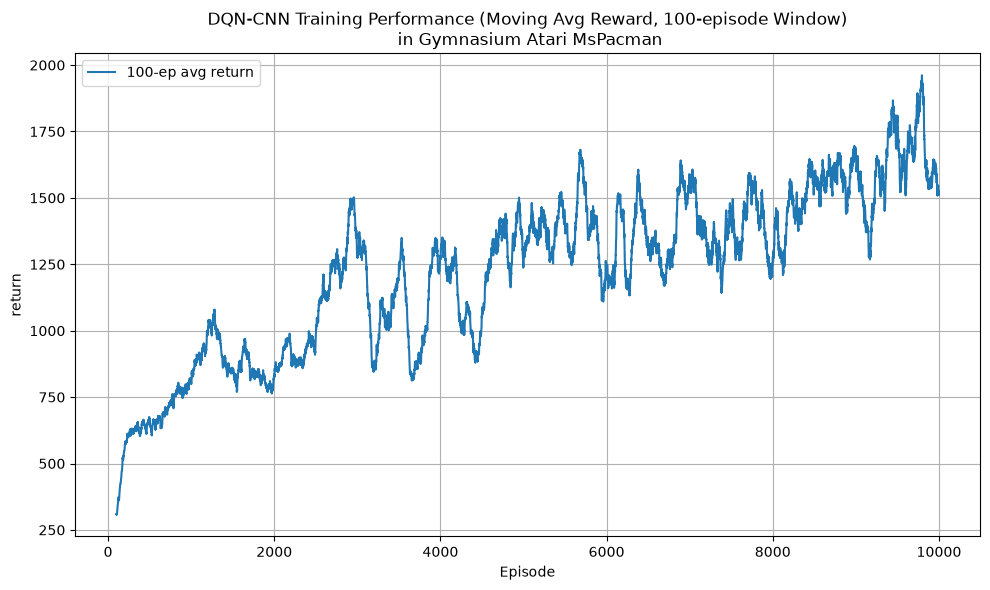

In [5]:


# Compute moving average of return (window=100)
train_df["return_ma100"] = train_df["return"].rolling(window=100).mean()


# Plot learning curves
plt.figure(figsize=(10,6))
plt.plot(train_df["episode"], train_df["return_ma100"], label="100-ep avg return")
plt.xlabel("Episode")
plt.ylabel("Average return")
plt.ylabel("return")
s = "DQN-CNN Training Performance (Moving Avg Reward, 100-episode Window)"
s = s + "\n in Gymnasium Atari MsPacman"
plt.title(s)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('DQN_CNN_Training_Atari.png', bbox_inches = 'tight')
plt.show()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 10000 to 10099
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  100 non-null    str    
 1   phase      100 non-null    str    
 2   episode    100 non-null    int64  
 3   return     100 non-null    int64  
 4   steps      100 non-null    int64  
 5   avg_loss   0 non-null      float64
 6   epsilon    0 non-null      float64
dtypes: float64(2), int64(3), str(2)
memory usage: 5.6 KB
  index       return        steps
0  mean  1120.600000   706.040000
1   min   150.000000   453.000000
2   max  2150.000000  1289.000000
3   std   647.006815   159.761307


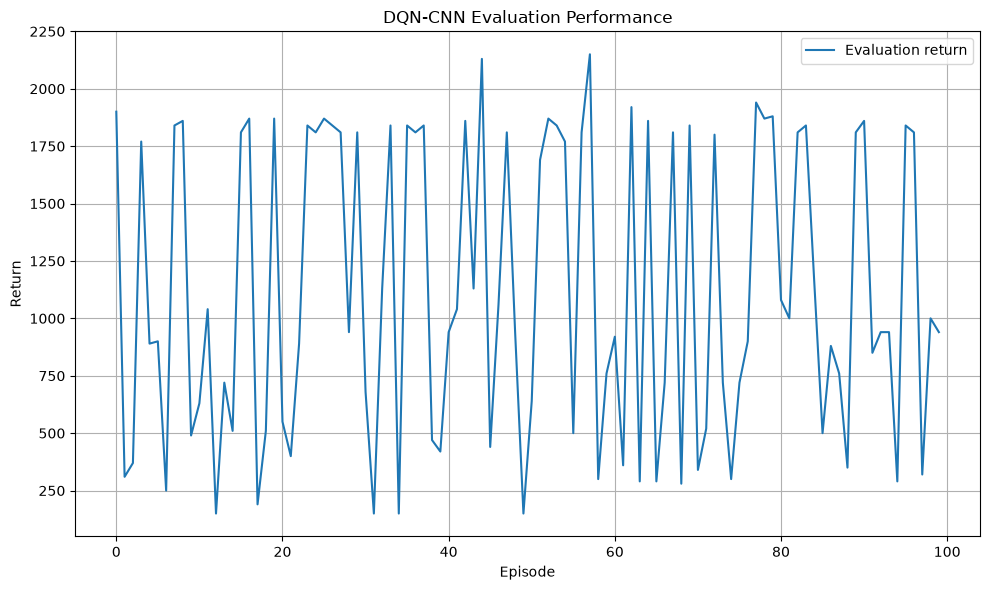

In [6]:
test_df = df[df["phase"] == "test"]
test_df.info()
summary = test_df.agg({
    "return": ["mean", "min", "max", "std"],
    "steps":  ["mean", "min", "max", "std"]
}).reset_index()

print(summary)

# Plot learning curves
plt.figure(figsize=(10,6))

plt.plot(
    test_df["episode"],
    test_df["return"],
    label="Evaluation return"
)
plt.legend()
plt.xlabel("Episode")
plt.ylabel("Return")

plt.title("DQN-CNN Evaluation Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# -----------------------------
# Imports for PyTorch
# -----------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam

import numpy as np
from collections import deque
import random
import csv, os, time, datetime
from datetime import datetime
import cv2
from copy import deepcopy

# -----------------------------
# Imports for Gym Atari MsPacman
# -----------------------------
import gymnasium as gym
import ale_py
from gymnasium.wrappers import FrameStackObservation

In [8]:
class AtariPreprocess(gym.ObservationWrapper):
    def __init__(self, env, height=84, width=84):
        super().__init__(env)
        self.height = height
        self.width = width
        self.observation_space = gym.spaces.Box(
            low=0, high=255, shape=(self.height, self.width), dtype=np.uint8
        )

    def observation(self, obs):
        # obs: (H, W, 3)
        gray = cv2.cvtColor(obs, cv2.COLOR_RGB2GRAY)
        resized = cv2.resize(gray, (self.width, self.height), interpolation=cv2.INTER_AREA)
        return resized.astype(np.uint8)


In [9]:
class MsPacmanDQN(nn.Module):
    """
    Deep Q-Network for Atari Ms. Pac-Man.

    This model follows the classic DQN convolutional architecture used by DeepMind:
    - Input: 4 stacked grayscale frames of size 84×84
    - Output: Q-values for each possible discrete action

    The network progressively extracts spatial features at multiple scales:
    - conv1: detects large patterns (corridors, ghosts, pellets)
    - conv2: detects medium-scale features (bends, junctions)
    - conv3: fine detail (local edges, fruit, Pac-Man shape)

    The final fully connected layers map the extracted representation
    into a vector of Q-values, one for each action.
    """

    def __init__(self, num_actions, in_channels=4):
        super().__init__()
        # Input: (batch, in_channels=4, 84, 84)

        # | Layer | Input → Output   | Kernel | Stride | Purpose                        |
        # | ----- | ---------------- | ------ | ------ | ------------------------------ |
        # | conv1 | 4 → 32 channels  | 8×8    | 4      | Capture large spatial patterns |
        # | conv2 | 32 → 64 channels | 4×4    | 2      | Detect medium patterns         |
        # | conv3 | 64 → 64 channels | 3×3    | 1      | Fine details                   |
        # These layers reduce the image spatial size from 84×84 → 7×7 (exactly as in DQN).

        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=8, stride=4)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=4, stride=2)
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1)


        # ---------------------------------------------------------
        # Fully Connected Layers (DQN "head")
        # ---------------------------------------------------------
        # Flatten 64 feature maps of size 7×7 = 3136 units.
        #
        # fc1:
        #   - Hidden layer with 512 units
        #   - Provides a dense, high-level representation of the scene.
        #
        # out:
        #   - Final layer, size = number of actions in the environment
        #   - Each output neuron is Q(s, a) for one specific action.
        # ---------------------------------------------------------

        # 84x84 → after convs this will be 7x7 if you follow the usual Atari setup
        # After the conv layers, the tensor is flattened:
        # 64 channels * 7 * 7 = 3136 numbers
        # This adds a fully-connected hidden layer with 512 units
        self.fc1 = nn.Linear(64 * 7 * 7, 512)
        self.out = nn.Linear(512, num_actions)


    def forward(self, x):
        # x expected as uint8 in [0,255] if coming straight from env
        # Normalize pixels
        # Input coming from Atari is uint8 in [0,255]
        # Dividing by 255 turns them into [0,1]
        # Three convolutional layers with ReLU
        # Flatten
        # Fully connected layer (512 units)
        # Output layer - Produces one Q-value per action

        # Normalize raw pixel values from [0, 255] → [0, 1]
        x = x / 255.0

        # Apply convolutional layers with ReLU activations
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))

        # Flatten all feature maps into a single vector per sample
        x = x.view(x.size(0), -1)

        # Fully connected layers (dense representation → Q-values)
        x = F.relu(self.fc1(x))
        return self.out(x)  # Q-values for all actions



In [10]:
def run_test_episode(qnet, env, device):
    # Reset environment and get the initial stacked frames
    obs, info = env.reset()
    state = np.array(obs, copy=False)   # Preprocessed observation (4 stacked frames)

    done = False
    episode_return = 0
    steps = 0

    # Put network in evaluation mode (disables dropout, batchnorm updates)
    qnet.eval()

    while not done:
        steps += 1

        # Convert state to a tensor on the correct device (1, 4, 84, 84)
        state_tensor = torch.as_tensor(
            state, dtype=torch.float32, device=device
        ).unsqueeze(0)

        # Greedy action selection: no epsilon, no gradients (pure evaluation)
        with torch.no_grad():
            q_values = qnet(state_tensor)
            action = q_values.argmax(dim=1).item()

        # Step the environment using the chosen action
        next_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Accumulate reward for episode score
        episode_return += reward

        # Update the state with the next stacked frames
        state = np.array(next_obs, copy=False)


    print(f"[Testing] episode: {episode}, return: {episode_return}, steps: {steps}")
    return episode_return, steps




In [11]:
# Now create an environment for testing (repeat_action_probability=0.25)
# Using ALE sticky actions is the standard, recommended, 
# and most academically accepted way to test Atari DQN performance.
test_env = gym.make(
    "ALE/MsPacman-v5",
    frameskip=4,
    repeat_action_probability=0.25,  # <-- stochasticity ON
    render_mode="human"
)
num_actions = test_env.action_space.n
test_env = AtariPreprocess(test_env)
test_env = FrameStackObservation(test_env, stack_size=4)

# Check available hardware
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print('Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Apple Metal Performance Shaders framework is available, using mps


In [12]:
qnet = MsPacmanDQN(num_actions, in_channels=4).to(device)
qnet.to(device)

MsPacmanDQN(
  (conv1): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
  (conv2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=3136, out_features=512, bias=True)
  (out): Linear(in_features=512, out_features=9, bias=True)
)

In [ ]:
if not os.path.exists("qnet_best.pt"):
    raise FileNotFoundError("qnet_best.pt not found")

state_dict = torch.load(
    "qnet_best.pt",
    map_location=device,
    weights_only=True
)
qnet.load_state_dict(state_dict)

num_episodes = 2
phase = "test"
print("Running", num_episodes, "Testing episodes")
for episode in range(num_episodes):
    episode_return, steps = run_test_episode(qnet, test_env, device)

Running 2 Testing episodes
[Testing] episode: 0, return: 510.0, steps: 641
